In [1]:
from google.colab import files

uploaded = files.upload()

Saving ai4i2020.csv to ai4i2020.csv


In [29]:
import pandas as pd
import numpy as np

file_name = next(iter(uploaded))

df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print("Column names:")
print(df.columns.tolist())

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [5]:
display(df.describe())

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
missing_values = df.isnull().sum()

print("Missing values per column:")
display(missing_values)

Missing values per column:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [7]:
missing_symbols = ["?", "-", "N/A", "na", "NULL", "null", "none", "", " "]

df = pd.read_csv("ai4i2020.csv", na_values=missing_symbols)

print("--- Missing Values After Handling Symbols ---")
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0])

--- Missing Values After Handling Symbols ---
Series([], dtype: int64)


In [8]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [9]:
for col in df.select_dtypes(include=['object', 'category', 'int64']).columns:
    print(f"Column: {col} -> Unique values: {df[col].unique()}")

Column: UDI -> Unique values: [    1     2     3 ...  9998  9999 10000]
Column: Product ID -> Unique values: ['M14860' 'L47181' 'L47182' ... 'M24857' 'H39412' 'M24859']
Column: Type -> Unique values: ['M' 'L' 'H']
Column: Rotational speed [rpm] -> Unique values: [1551 1408 1498 1433 1425 1558 1527 1667 1741 1782 1423 1339 1742 2035
 1542 1311 1410 1306 1632 1375 1450 1581 1758 1561 1861 1512 1811 1439
 1693 1798 1419 1665 1559 1452 1379 1350 1362 1368 1372 1472 1489 1843
 1418 1412 2861 1383 1497 1565 1691 1477 1513 1661 1378 1393 1592 1829
 1812 1523 1394 1679 1466 1924 1369 1601 1461 1455 1398 1402 1445 1453
 1469 1422 1804 1436 1544 1487 1753 1830 1727 1622 1351 1575 1750 1529
 1852 1991 1555 1441 1591 1621 1572 1872 1499 1486 1680 1431 1564 1599
 1707 1467 1310 1546 1560 1329 1413 1587 1473 1737 1430 1711 1420 1297
 1449 1268 1511 1778 1407 1391 1612 1515 1463 1584 1850 1528 1987 1495
 1478 1471 1282 1586 1468 1440 1733 1458 1318 1610 1462 1382 1618 1988
 1304 1475 1824 1342 1485 1

<Axes: >

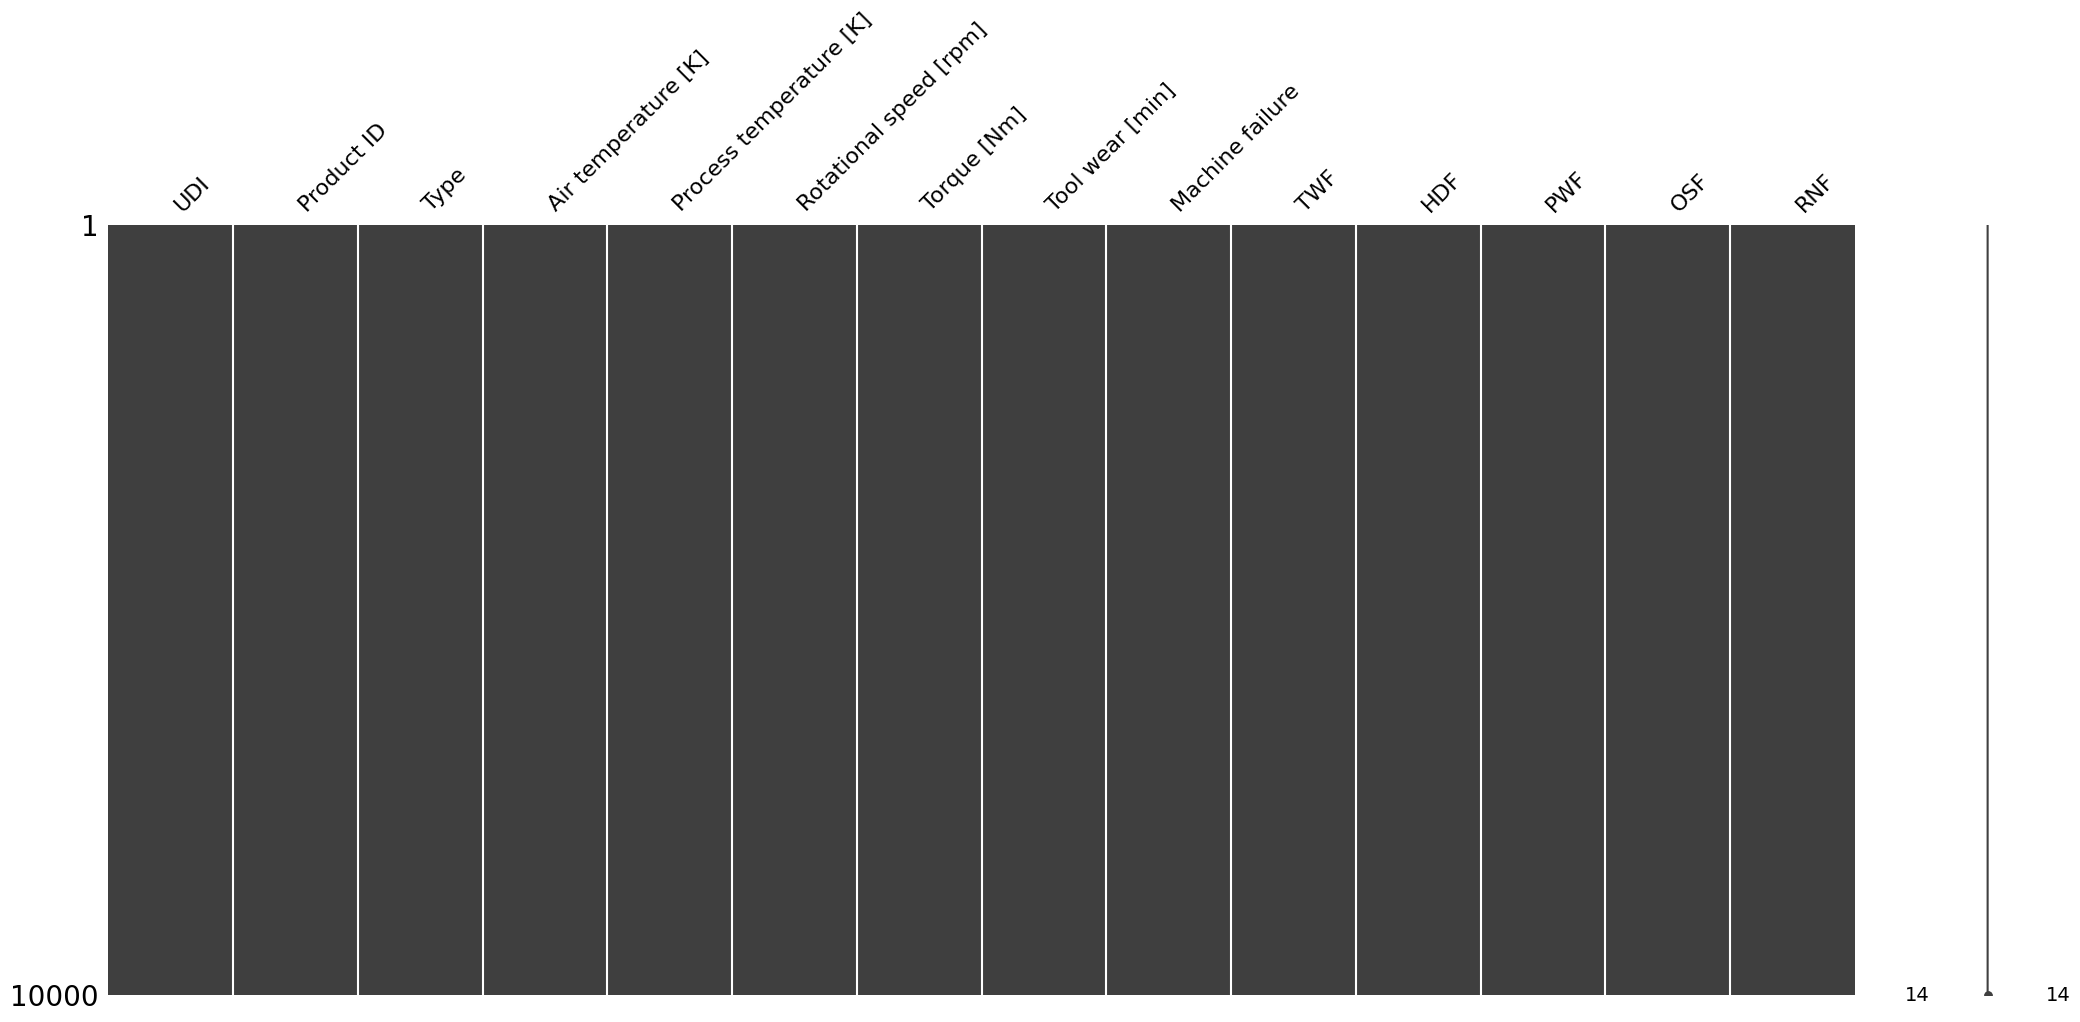

In [10]:
import missingno as msno

msno.matrix(df)

In [11]:
column_info = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values
})

display(column_info)

,Column,Data Type,Unique Values
0,UDI,int64,10000
1,Product ID,object,10000
2,Type,object,3
3,Air temperature [K],float64,93
4,Process temperature [K],float64,82
5,Rotational speed [rpm],int64,941
6,Torque [Nm],float64,577
7,Tool wear [min],int64,246
8,Machine failure,int64,2
9,TWF,int64,2


In [12]:
print("Product types:")
print(df["Type"].value_counts())

print("\nMachine failure values:")
print(df["Machine failure"].value_counts())

print("\nFailure indicator values:")
for col in ["TWF", "HDF", "PWF", "OSF", "RNF"]:
    print(f"{col}: {sorted(df[col].unique())}")

Product types:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Machine failure values:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure indicator values:
TWF: [np.int64(0), np.int64(1)]
HDF: [np.int64(0), np.int64(1)]
PWF: [np.int64(0), np.int64(1)]
OSF: [np.int64(0), np.int64(1)]
RNF: [np.int64(0), np.int64(1)]


In [13]:
failure_counts = df["Machine failure"].value_counts().sort_index()

failure_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage": failure_counts / len(df) * 100
})

failure_summary.index = ["No Failure (0)", "Failure (1)"]

display(failure_summary.round(2))

,Count,Percentage
No Failure (0),9661,96.61
Failure (1),339,3.39


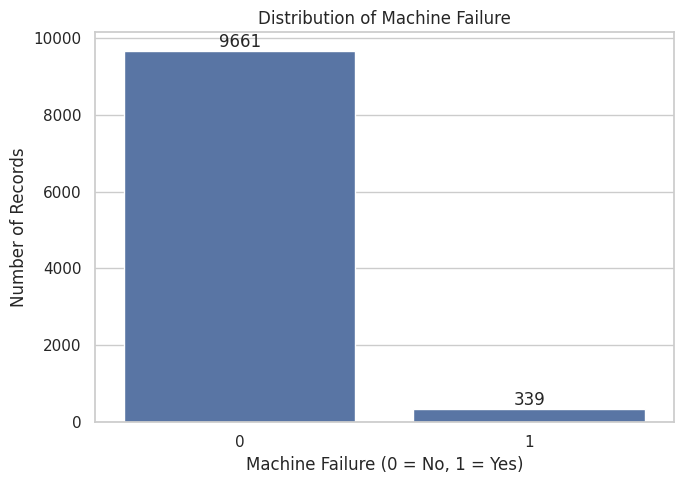

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

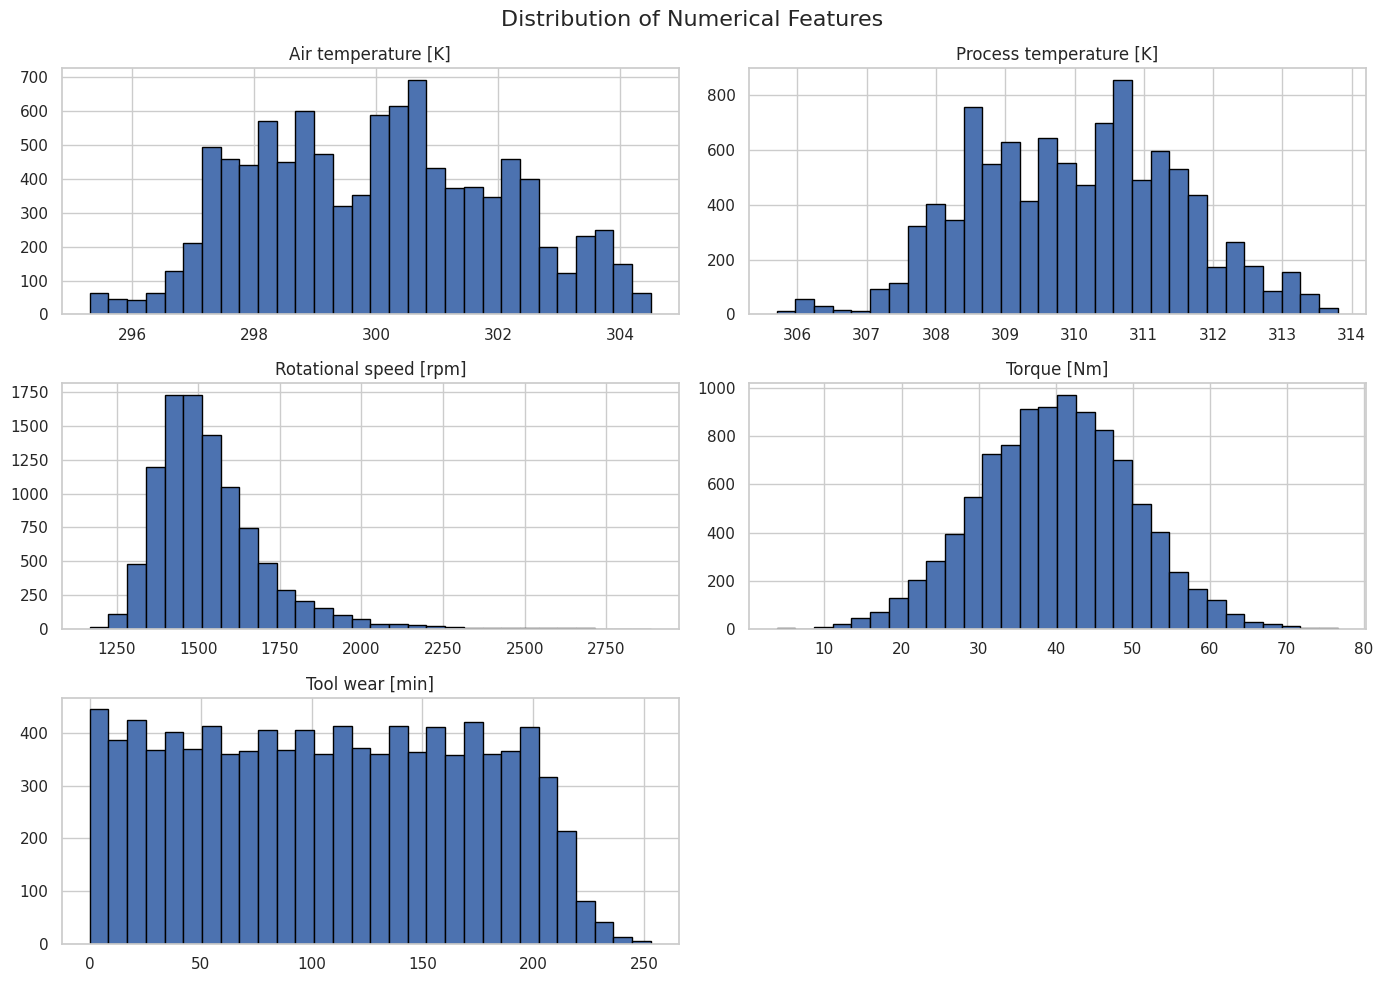

In [15]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numeric_features].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [16]:
outlier_results = []

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers.sum(),
        "Outlier Percentage": outliers.mean() * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Air temperature [K],293.50,306.30,0,0.00
1,Process temperature [K],305.35,314.55,0,0.00
2,Rotational speed [rpm],1139.50,1895.50,418,4.18
3,Torque [Nm],12.80,67.20,69,0.69
4,Tool wear [min],-110.50,325.50,0,0.00


In [17]:
for col in ["Rotational speed [rpm]", "Torque [Nm]"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nFeature: {col}")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Outliers: {len(outliers)}")

    print("\nFailure distribution among outliers:")
    print(outliers["Machine failure"].value_counts())

    print("\nFailure rate among outliers (%):")
    print(
        outliers["Machine failure"].mean() * 100
        if len(outliers) > 0 else 0
    )



Feature: Rotational speed [rpm]
Lower bound: 1139.50
Upper bound: 1895.50
Outliers: 418

Failure distribution among outliers:
Machine failure
0    383
1     35
Name: count, dtype: int64

Failure rate among outliers (%):
8.373205741626794

Feature: Torque [Nm]
Lower bound: 12.80
Upper bound: 67.20
Outliers: 69

Failure distribution among outliers:
Machine failure
1    62
0     7
Name: count, dtype: int64

Failure rate among outliers (%):
89.85507246376811


In [18]:

features = {
    "Rotational speed [rpm]": (1139.5, 1895.5),
    "Torque [Nm]": (12.8, 67.2)
}

for col, (lower, upper) in features.items():
    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")

    lower_outliers = df[df[col] < lower]
    upper_outliers = df[df[col] > upper]

    for label, subset in [
        ("Lower outliers", lower_outliers),
        ("Upper outliers", upper_outliers)
    ]:
        print(f"\n{label}: {len(subset)}")

        if len(subset) > 0:
            print("Minimum:", subset[col].min())
            print("Maximum:", subset[col].max())
            print(
                "Failure count:",
                subset["Machine failure"].sum()
            )
            print(
                "Failure rate (%):",
                round(subset["Machine failure"].mean() * 100, 2)
            )



Feature: Rotational speed [rpm]

Lower outliers: 0

Upper outliers: 418
Minimum: 1896
Maximum: 2886
Failure count: 35
Failure rate (%): 8.37

Feature: Torque [Nm]

Lower outliers: 24
Minimum: 3.8
Maximum: 12.7
Failure count: 22
Failure rate (%): 91.67

Upper outliers: 40
Minimum: 67.3
Maximum: 76.6
Failure count: 36
Failure rate (%): 90.0


In [19]:
col = "Torque [Nm]"

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

lower_outliers = df[df[col] < lower]
upper_outliers = df[df[col] > upper]

print(f"Q1: {Q1:.4f}")
print(f"Q3: {Q3:.4f}")
print(f"IQR: {IQR:.4f}")
print(f"Exact lower bound: {lower:.4f}")
print(f"Exact upper bound: {upper:.4f}")

print("Lower outliers:", len(lower_outliers))
print("Upper outliers:", len(upper_outliers))
print("Total outliers:", len(lower_outliers) + len(upper_outliers))

Q1: 33.2000
Q3: 46.8000
IQR: 13.6000
Exact lower bound: 12.8000
Exact upper bound: 67.2000
Lower outliers: 28
Upper outliers: 41
Total outliers: 69


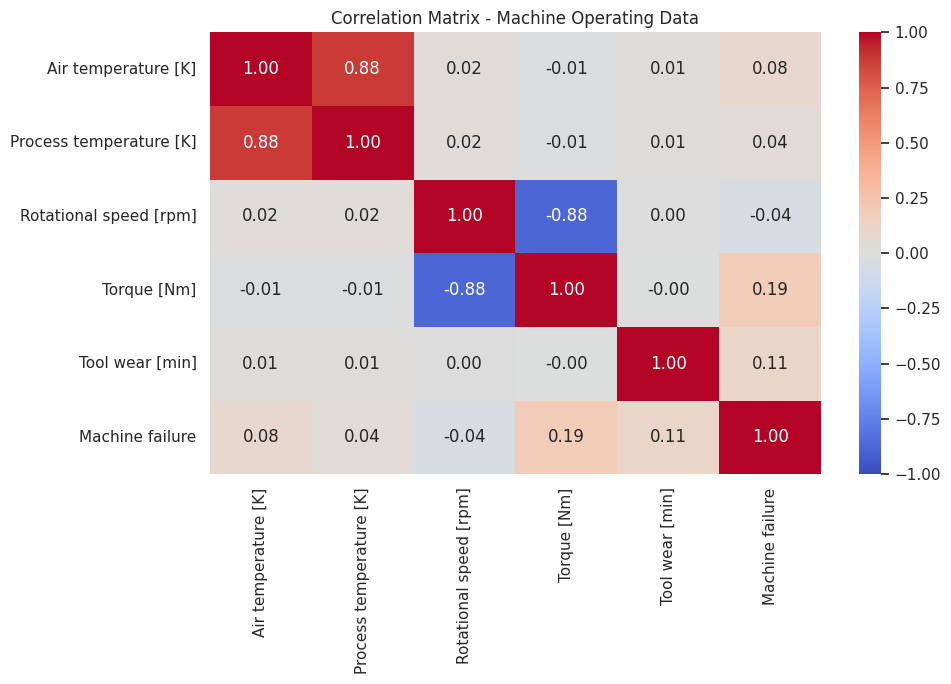

In [20]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

corr_matrix = df[features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix - Machine Operating Data")
plt.tight_layout()
plt.show()

In [21]:

# Step 16: Data validation

# 1. Check unique identifiers
print("Unique UDI values:", df["UDI"].nunique())
print("Unique Product IDs:", df["Product ID"].nunique())

# 2. Check physically invalid negative values
numeric_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

print("\nNegative values per feature:")
display((df[numeric_cols] < 0).sum())

# 3. Check failure indicators
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

print("\nFailure indicator value counts:")
for col in failure_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index())

# 4. Compare the main failure target with failure indicators
indicator_failure = (df[failure_cols].sum(axis=1) > 0).astype(int)

print("\nMain target distribution:")
print(df["Machine failure"].value_counts())

print("\nRows with a failure indicator but no main failure:")
print(((indicator_failure == 1) & (df["Machine failure"] == 0)).sum())


Unique UDI values: 10000
Unique Product IDs: 10000

Negative values per feature:


,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0



Failure indicator value counts:

TWF:
TWF
0    9954
1      46
Name: count, dtype: int64

HDF:
HDF
0    9885
1     115
Name: count, dtype: int64

PWF:
PWF
0    9905
1      95
Name: count, dtype: int64

OSF:
OSF
0    9902
1      98
Name: count, dtype: int64

RNF:
RNF
0    9981
1      19
Name: count, dtype: int64

Main target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Rows with a failure indicator but no main failure:
18


In [22]:
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Records with a failure indicator but Machine failure = 0
mismatch = df[
    (df[failure_cols].sum(axis=1) > 0) &
    (df["Machine failure"] == 0)
]

print("Number of mismatched records:", len(mismatch))

display(mismatch[
    ["UDI", "Product ID", "Type"] +
    failure_cols +
    ["Machine failure"]
])

Number of mismatched records: 18


,UDI,Product ID,Type,TWF,HDF,PWF,OSF,RNF,Machine failure
1221,1222,M16081,M,0,0,0,0,1,0
1302,1303,L48482,L,0,0,0,0,1,0
1748,1749,H31162,H,0,0,0,0,1,0
2072,2073,L49252,L,0,0,0,0,1,0
2559,2560,L49739,L,0,0,0,0,1,0
3065,3066,M17925,M,0,0,0,0,1,0
3452,3453,H32866,H,0,0,0,0,1,0
5471,5472,L52651,L,0,0,0,0,1,0
5489,5490,L52669,L,0,0,0,0,1,0
5495,5496,H34909,H,0,0,0,0,1,0


In [23]:
# Step 17: Select features and target

feature_cols = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target_col = "Machine failure"

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature data types:")
print(X.dtypes)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (10000, 6)
Target shape: (10000,)

Feature data types:
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [24]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (8000, 6)
Testing features: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [25]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessor created successfully!")


Preprocessor created successfully!


In [26]:

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("\nFeature names:")
print(preprocessor.get_feature_names_out())


Processed training shape: (8000, 8)
Processed testing shape: (2000, 8)

Feature names:
['categorical__Type_H' 'categorical__Type_L' 'categorical__Type_M'
 'numerical__Air temperature [K]' 'numerical__Process temperature [K]'
 'numerical__Rotational speed [rpm]' 'numerical__Torque [Nm]'
 'numerical__Tool wear [min]']


In [27]:

# Create a clean copy without changing the original dataset
df_clean = df.copy()

# Verify data quality
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

# Save the cleaned dataset
output_file = "AI4I_2020_cleaned.csv"
df_clean.to_csv(output_file, index=False)

print(f"\nCleaned dataset saved as: {output_file}")


Missing values: 0
Duplicate rows: 0

Cleaned dataset saved as: AI4I_2020_cleaned.csv


In [30]:
from google.colab import files

files.download("AI4I_2020_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>